# 5. Coarse Behavioral Hierarchy & What Each Physical Field Separates

**What you will learn:**
1. At coarse resolutions on `Top-1`, missions never merge haphazardly — they merge into **two clean motion families** while **Homing** stays separate until the coarsest end.
2. Which **specific physical field** (density $\rho_\sigma$, kinetic intensity $K_\sigma$, divergence $\varphi_\sigma$, vorticity $\psi_\sigma$, Jacobi coupling $J_\sigma$) distinguishes every pair of missions.
3. Why **`D-Gate + Foraging`** is separated best by **vorticity $\psi_\sigma$**, **`Shelter + XOR`** is separated best by **divergence $\varphi_\sigma$**, and **`Homing`** acts as a hybrid signature bridging patches ($\rho_\sigma$) and full-arena cruising ($K_\sigma$).

In [1]:
import pickle, sys
from pathlib import Path
from IPython.display import Image, display
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.cluster import contingency_matrix

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
load = lambda p: pickle.load(open(p, "rb"))

## 1. The Extended Top-1 Grid & Exact Merge Order

Across every neighborhood large enough to merge inside the Top-1 extended grid (`k_nn` up to `50`), **Directional Gate + Foraging** (continuous traffic) joins first, followed by **Shelter + XOR Aggregation** (patch gathering), while **Homing** remains isolated (`C=3`). Let's visualize the extended grid alongside clean **contingency heatmaps** at exact $C=4, 3, 2$ states!

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_fusion_sequence.pdf


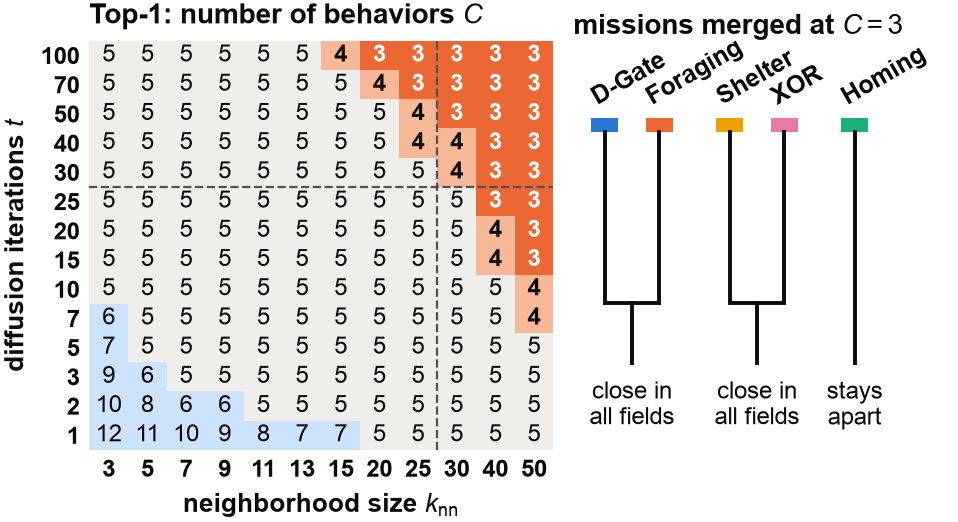

Merge log across Top-1 extended grid:
  k_nn=15, t=100: C=4, purity=0.800 -> D-Gate + Foraging
  k_nn=20, t= 70: C=4, purity=0.796 -> Shelter + XOR
  k_nn=20, t=100: C=3, purity=0.600 -> D-Gate + Foraging; Shelter + XOR
  k_nn=25, t= 40: C=4, purity=0.796 -> Shelter + XOR
  k_nn=25, t= 70: C=3, purity=0.600 -> D-Gate + Foraging; Shelter + XOR
  k_nn=30, t= 30: C=4, purity=0.796 -> Shelter + XOR
  k_nn=30, t= 50: C=3, purity=0.600 -> D-Gate + Foraging; Shelter + XOR
  k_nn=40, t= 15: C=4, purity=0.796 -> Shelter + XOR
  k_nn=40, t= 25: C=3, purity=0.600 -> D-Gate + Foraging; Shelter + XOR
  k_nn=50, t=  7: C=4, purity=0.796 -> Shelter + XOR
  k_nn=50, t= 15: C=3, purity=0.600 -> D-Gate + Foraging; Shelter + XOR


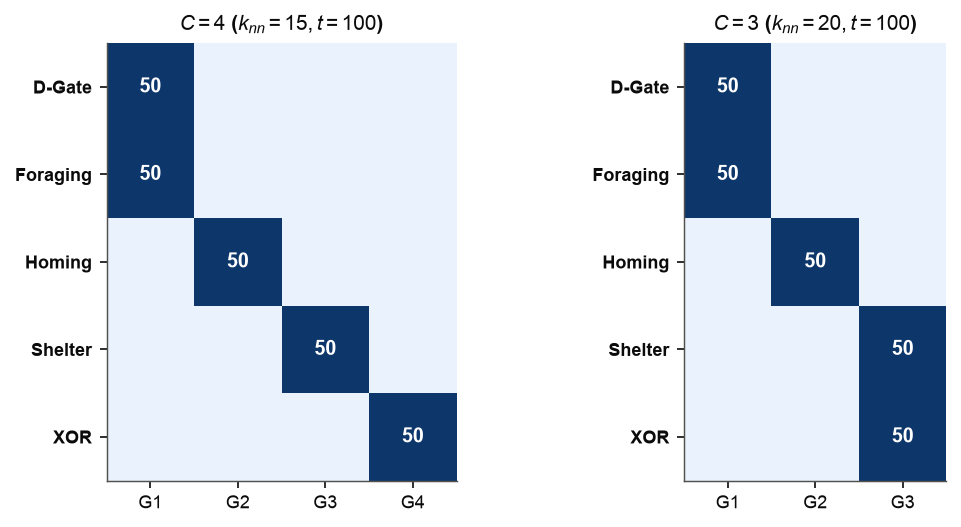

In [2]:
M.fig_fusion_sequence()
display(Image(filename=str(ROOT / "figures/fig_fusion_sequence.png"), width=900))

E = load(PAPER / "extended_top1.pkl")
y = E["labels"]
names = L.MSHORT

def merged(pred):
    home = {}
    for m in np.unique(y):
        home.setdefault(int(np.bincount(pred[y == m]).argmax()), []).append(names[m])
    return [" + ".join(g) for g in home.values() if len(g) > 1]

print("Merge log across Top-1 extended grid:")
for k in E["knns"]:
    last = None
    for r in sorted((r for r in E["results"] if r["knn"] == k), key=lambda r: r["t"]):
        g = merged(r["pred"])
        if g and g != last:
            print(f"  k_nn={k:2d}, t={r['t']:3d}: C={r['C']}, purity={r['purity']:.3f} -> {'; '.join(g)}")
            last = g

# Pick one representative C=4, C=3, and C=2 partition to render cleanly
picks = {}
for target_c in (4, 3, 2):
    for r in sorted(E["results"], key=lambda r: (r["knn"], r["t"])):
        if r["C"] == target_c:
            picks[target_c] = r; break

fig, axes = plt.subplots(1, len(picks), figsize=(3.9 * len(picks), 3.6))
if len(picks) == 1:
    axes = [axes]
for ax, (tc, r) in zip(axes, picks.items()):
    cm = contingency_matrix(y, r["pred"])
    ax.imshow(cm, cmap=L.SEQ, vmin=0, vmax=50)
    for ii in range(cm.shape[0]):
        for jj in range(cm.shape[1]):
            v = cm[ii, jj]
            if v > 0:
                ax.text(jj, ii, str(v), ha="center", va="center", color="white" if v > 25 else L.INK, fontweight="bold")
    ax.set_yticks(range(5)); ax.set_yticklabels(names, fontweight="bold")
    ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels([f"G{j+1}" for j in range(cm.shape[1])])
    ax.set_title(f"$C={tc}$ ($k_{{nn}}={r['knn']}, t={r['t']}$)", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

## 2. Which Physical Field Separates Which Pair?

To see *why* missions merge in this exact order, we compute the **separation ratio** (mean rank distance *between* two missions divided by mean rank distance *within* them, averaged across $\sigma_1\dots\sigma_4$):

* **D-Gate / Foraging (`3.35` in $\psi_\sigma$)**: Nearly indistinguishable in density and convergence (`1.19` in $\varphi_\sigma$), separated mainly by **how trajectories circulate** (vorticity $\psi_\sigma$).
* **Shelter / XOR (`3.34` in $\varphi_\sigma$)**: Both settle into compact patches (`1.53` in $K_\sigma$, `1.99` in $\rho_\sigma$), separated best by **where net flux converges** (divergence potential $\varphi_\sigma$, followed by $J_\sigma = 2.75$).
* **Homing**: Combines a compact resting nest (low distance to XOR/Shelter in $\rho_\sigma$) with full-arena initial transit (high $K_\sigma$, separating Homing from Shelter at `6.49` and from Foraging in $\varphi_\sigma$ at `7.27`).

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_pair_separation.pdf


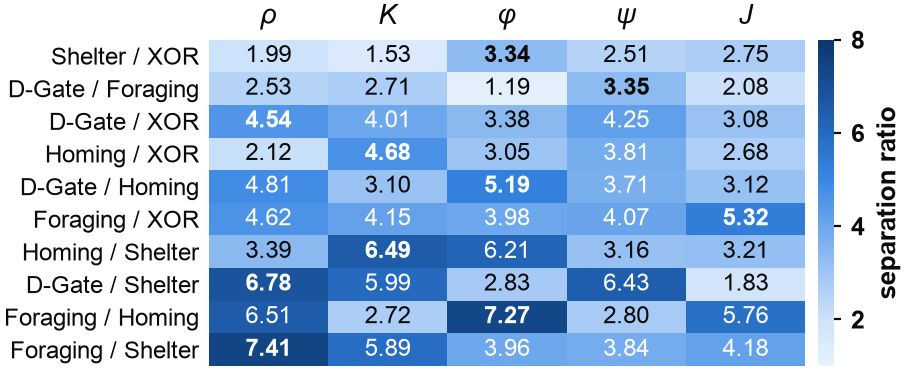

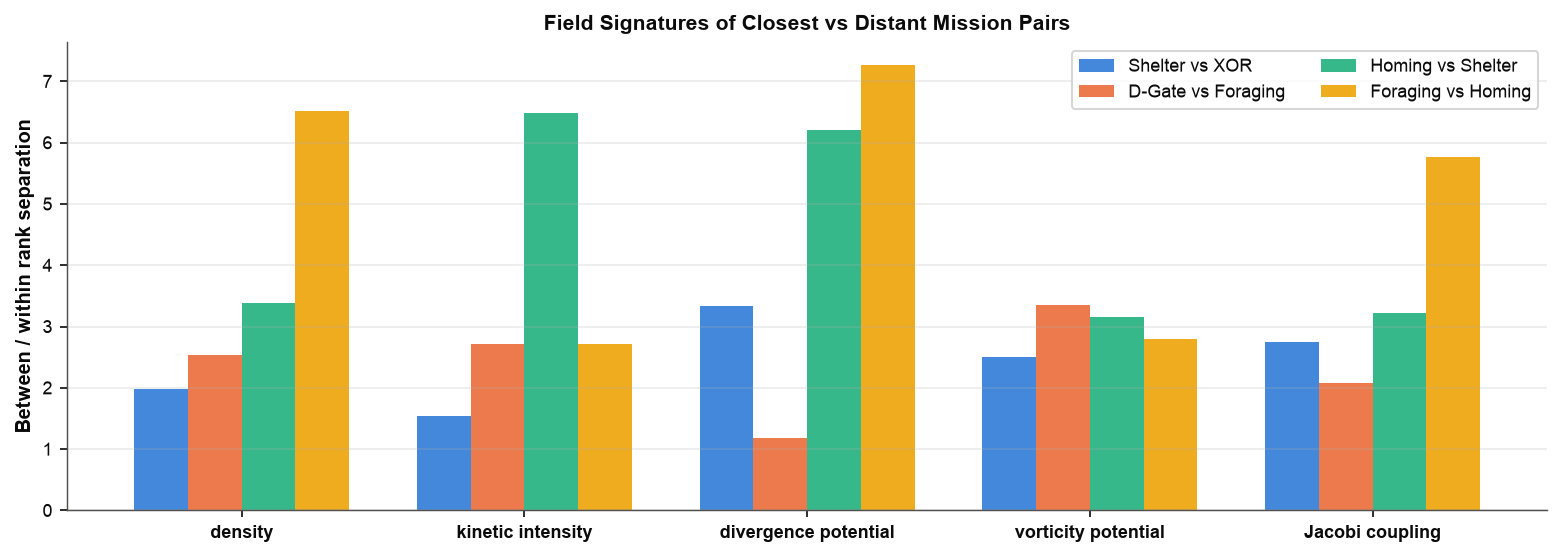

In [3]:
R, pairs = M.fig_pair_separation()
display(Image(filename=str(ROOT / "figures/fig_pair_separation.png"), width=900))

# Focus bar chart comparing the two closest pairs vs a well-separated pair
idx_focus = [i for i, (a, b) in enumerate(pairs) if (a, b) in [(3, 4), (0, 1), (2, 3), (1, 2)]]
fig, ax = plt.subplots(figsize=(10.5, 3.8))
x = np.arange(len(L.FIELDS)); w = 0.19
for k, p_idx in enumerate(idx_focus):
    a, b = pairs[p_idx]
    vals = R[:, p_idx]
    ax.bar(x + (k - 1.5) * w, vals, width=w, color=L.MCOL[k], alpha=0.88, label=f"{L.MSHORT[a]} vs {L.MSHORT[b]}")
ax.set_xticks(x); ax.set_xticklabels([L.FNAME[f] for f in L.FIELDS], fontweight="bold")
ax.set_ylabel("Between / within rank separation"); ax.set_title("Field Signatures of Closest vs Distant Mission Pairs", fontweight="bold")
ax.legend(fontsize=8.5, ncol=2); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 3. Borderline Trajectories Near Transition (`figA_merge`)

Why do a small subset of **XOR Aggregation** runs sit near **Shelter** before merging (and shift if mutual-rank normalization is omitted)? Because their robots wander continuously through most of the run and settle on black areas only near the end — matching Shelter's time-averaged motion profile!

saved /home/ndinga/Documents/paper_topological_kinematics/figures/figA_merge.pdf


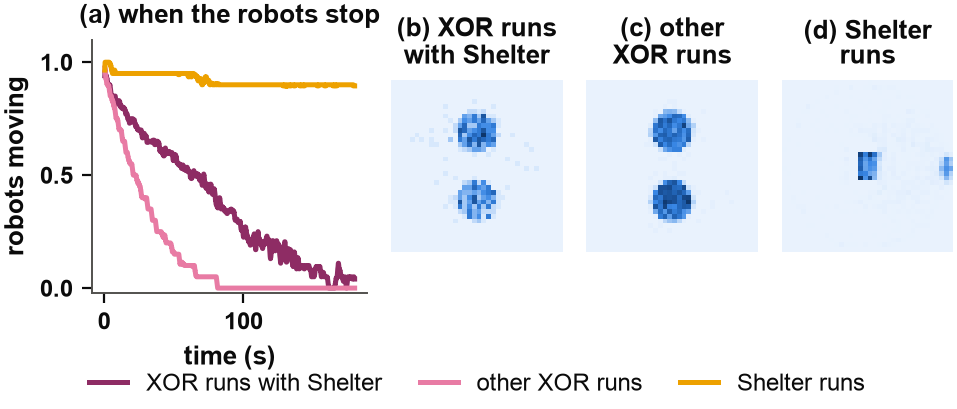

In [4]:
M.fig_merge()
display(Image(filename=str(ROOT / "figures/figA_merge.png"), width=860))